# <span style="color:red"><center>Transformer Chatbot</center></span>

Implementación de un Transformer para chatbot conversacional (API funcional de Keras) — compatible con **TensorFlow 2.16+ / Keras 3 / Python 3.12**.

## <span style="color:blue">Referencias</span>
1. [Attention Is All You Need (Vaswani et. al, 2017)](https://arxiv.org/pdf/1706.03762.pdf)
2. [Tutorial Transformer de Google](https://www.tensorflow.org/text/tutorials/transformer)
3. [Cornell Movie-Dialogs Corpus](https://www.cs.cornell.edu/~cristian/Cornell_Movie-Dialogs_Corpus.html)

## <span style="color:blue">Importa librerías</span>

In [97]:
import os
import re
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from time import time
from collections import Counter

tf.random.set_seed(1234)
AUTO = tf.data.AUTOTUNE

print("TensorFlow version {}".format(tf.__version__))
print("Keras version      {}".format(tf.keras.__version__))

TensorFlow version 2.17.1
Keras version      3.9.2


### Inicialización de GPU / TPU

In [98]:
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver()
    print('Running on TPU {}'.format(tpu.cluster_spec().as_dict()['worker']))
except ValueError:
    tpu = None

if tpu:
    tf.config.experimental_connect_to_cluster(tpu)
    tf.tpu.experimental.initialize_tpu_system(tpu)
    strategy = tf.distribute.TPUStrategy(tpu)
else:
    strategy = tf.distribute.get_strategy()

print("REPLICAS: {}".format(strategy.num_replicas_in_sync))

REPLICAS: 1


## <span style="color:blue">Hiperparámetros</span>

In [99]:
MAX_LENGTH = 40
MAX_SAMPLES = 25000

BATCH_SIZE = 64 * strategy.num_replicas_in_sync
BUFFER_SIZE = 20000

NUM_LAYERS = 4
D_MODEL = 512
NUM_HEADS = 8
UNITS = 512
DROPOUT = 0.1

EPOCHS = 100   # sube a 40 si tienes GPU y tiempo

## <span style="color:blue">Prepara el Dataset</span>

Usamos [Cornell Movie-Dialogs Corpus](https://www.cs.cornell.edu/~cristian/Cornell_Movie-Dialogs_Corpus.html).

In [100]:
path_to_zip = tf.keras.utils.get_file(
    'cornell_movie_dialogs.zip',
    origin='http://www.cs.cornell.edu/~cristian/data/cornell_movie_dialogs_corpus.zip',
    extract=True,
    cache_dir='.',
    cache_subdir='.'
)

base_dir = os.path.dirname(path_to_zip)
path_to_movie_lines = None
path_to_movie_conversations = None
for root, dirs, files in os.walk(base_dir):
    if 'movie_lines.txt' in files and 'movie_conversations.txt' in files:
        path_to_movie_lines = os.path.join(root, 'movie_lines.txt')
        path_to_movie_conversations = os.path.join(root, 'movie_conversations.txt')
        break

print(path_to_movie_lines)
print(path_to_movie_conversations)
assert path_to_movie_lines is not None, 'No se encontró movie_lines.txt'

././cornell_movie_dialogs_extracted/cornell movie-dialogs corpus/movie_lines.txt
././cornell_movie_dialogs_extracted/cornell movie-dialogs corpus/movie_conversations.txt


### Cargar y preprocesar datos

In [101]:
def preprocess_sentence(sentence):
    sentence = sentence.lower().strip()
    sentence = re.sub(r"([?.!,])", r" \1 ", sentence)
    sentence = re.sub(r'[" \t]+', " ", sentence)
    sentence = re.sub(r"i'm", "i am", sentence)
    sentence = re.sub(r"he's", "he is", sentence)
    sentence = re.sub(r"she's", "she is", sentence)
    sentence = re.sub(r"it's", "it is", sentence)
    sentence = re.sub(r"that's", "that is", sentence)
    sentence = re.sub(r"what's", "that is", sentence)
    sentence = re.sub(r"where's", "where is", sentence)
    sentence = re.sub(r"how's", "how is", sentence)
    sentence = re.sub(r"\'ll", " will", sentence)
    sentence = re.sub(r"\'ve", " have", sentence)
    sentence = re.sub(r"\'re", " are", sentence)
    sentence = re.sub(r"\'d", " would", sentence)
    sentence = re.sub(r"won't", "will not", sentence)
    sentence = re.sub(r"can't", "cannot", sentence)
    sentence = re.sub(r"n't", " not", sentence)
    sentence = re.sub(r"n'", "ng", sentence)
    sentence = re.sub(r"'bout", "about", sentence)
    sentence = re.sub(r"[^a-zA-Z?.!,]+", " ", sentence)
    sentence = sentence.strip()
    return sentence


def load_conversations():
    id2line = {}
    with open(path_to_movie_lines, errors='ignore') as file:
        lines = file.readlines()
    for line in lines:
        parts = line.replace('\n', '').split(' +++$+++ ')
        if len(parts) == 5:
            id2line[parts[0]] = parts[4]

    inputs, outputs = [], []
    with open(path_to_movie_conversations, 'r') as file:
        lines = file.readlines()
    for line in lines:
        parts = line.replace('\n', '').split(' +++$+++ ')
        if len(parts) < 4:
            continue
        conversation = [line[1:-1] for line in parts[3][1:-1].split(', ')]
        for i in range(len(conversation) - 1):
            if conversation[i] in id2line and conversation[i+1] in id2line:
                inputs.append(preprocess_sentence(id2line[conversation[i]]))
                outputs.append(preprocess_sentence(id2line[conversation[i + 1]]))
                if len(inputs) >= MAX_SAMPLES:
                    return inputs, outputs
    return inputs, outputs


questions, answers = load_conversations()
print('Muestra de una pregunta:', questions[20])
print('Muestra de una respuesta:', answers[20])
print('Total muestras:', len(questions))

Muestra de una pregunta: i really , really , really wanna go , but i cannot . not unless my sister goes .
Muestra de una respuesta: i am working on it . but she does not seem to be going for him .
Total muestras: 25000


### Construir el vocabulario (tokenizador autocontenido)

In [102]:
MAX_WORDS = 2**13 - 2

counter = Counter()
for text in questions + answers:
    counter.update(text.split())

top_words = [w for w, _ in counter.most_common(MAX_WORDS - 2)]

PAD_ID = 0
UNK_ID = 1
vocab = ['<pad>', '<unk>'] + top_words
word_to_id = {w: i for i, w in enumerate(vocab)}
id_to_word = {i: w for w, i in word_to_id.items()}

actual_max_index = len(vocab) - 1
START_TOKEN_ID = actual_max_index + 1
END_TOKEN_ID   = actual_max_index + 2
VOCAB_SIZE     = actual_max_index + 3

START_TOKEN = [START_TOKEN_ID]
END_TOKEN   = [END_TOKEN_ID]

print('Tamaño del vocabulario (palabras):', len(vocab))
print('START_TOKEN_ID:', START_TOKEN_ID)
print('END_TOKEN_ID  :', END_TOKEN_ID)
print('VOCAB_SIZE    :', VOCAB_SIZE)


def encode(sentence):
    return [word_to_id.get(w, UNK_ID) for w in sentence.split()]


def decode(ids):
    result = []
    for i in ids:
        i = int(i)
        if i in (PAD_ID, START_TOKEN_ID, END_TOKEN_ID):
            continue
        result.append(id_to_word.get(i, '<unk>'))
    return ' '.join(result)


print('Tokenización ejemplo:', encode(questions[20])[:10], '...')

Tamaño del vocabulario (palabras): 8190
START_TOKEN_ID: 8190
END_TOKEN_ID  : 8191
VOCAB_SIZE    : 8192
Tokenización ejemplo: [5, 103, 3, 103, 3, 103, 375, 60, 3, 37] ...


### Tokenizar, filtrar y rellenar sentencias

In [103]:
def tokenize_and_filter(inputs, outputs):
    tokenized_inputs, tokenized_outputs = [], []
    for (sentence1, sentence2) in zip(inputs, outputs):
        sentence1 = START_TOKEN + encode(sentence1) + END_TOKEN
        sentence2 = START_TOKEN + encode(sentence2) + END_TOKEN
        if len(sentence1) <= MAX_LENGTH and len(sentence2) <= MAX_LENGTH:
            tokenized_inputs.append(sentence1)
            tokenized_outputs.append(sentence2)

    tokenized_inputs = tf.keras.preprocessing.sequence.pad_sequences(
        tokenized_inputs, maxlen=MAX_LENGTH, padding='post')
    tokenized_outputs = tf.keras.preprocessing.sequence.pad_sequences(
        tokenized_outputs, maxlen=MAX_LENGTH, padding='post')
    return tokenized_inputs, tokenized_outputs


questions, answers = tokenize_and_filter(questions, answers)
print('Tamaño del vocabulario: {}'.format(VOCAB_SIZE))
print('Número de muestras: {}'.format(len(questions)))
print('Forma de questions:', questions.shape)
print('Forma de answers  :', answers.shape)

Tamaño del vocabulario: 8192
Número de muestras: 22530
Forma de questions: (22530, 40)
Forma de answers  : (22530, 40)


### Crea el `tf.data.Dataset`

In [104]:
dataset = tf.data.Dataset.from_tensor_slices((
    {
        'inputs': questions,
        'dec_inputs': answers[:, :-1]
    },
    answers[:, 1:]
))

dataset = dataset.cache()
dataset = dataset.shuffle(BUFFER_SIZE)
dataset = dataset.batch(BATCH_SIZE)
dataset = dataset.prefetch(AUTO)

print(dataset)

<_PrefetchDataset element_spec=({'inputs': TensorSpec(shape=(None, 40), dtype=tf.int32, name=None), 'dec_inputs': TensorSpec(shape=(None, 39), dtype=tf.int32, name=None)}, TensorSpec(shape=(None, 39), dtype=tf.int32, name=None))>


## <span style="color:blue">Atención</span>

### Producto punto escalado

In [105]:
def scaled_dot_product_attention(query, key, value, mask=None):
    matmul_qk = tf.matmul(query, key, transpose_b=True)
    depth = tf.cast(tf.shape(key)[-1], tf.float32)
    logits = matmul_qk / tf.math.sqrt(depth)
    if mask is not None:
        logits += (mask * -1e9)
    attention_weights = tf.nn.softmax(logits, axis=-1)
    output = tf.matmul(attention_weights, value)
    return output

### Atención multi-cabeza

In [106]:
class MultiHeadAttention(tf.keras.layers.Layer):

    def __init__(self, d_model, num_heads, name="multi_head_attention", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_heads = num_heads
        self.d_model = d_model
        assert d_model % self.num_heads == 0
        self.depth = d_model // self.num_heads
        self.query_dense = tf.keras.layers.Dense(units=d_model)
        self.key_dense   = tf.keras.layers.Dense(units=d_model)
        self.value_dense = tf.keras.layers.Dense(units=d_model)
        self.dense       = tf.keras.layers.Dense(units=d_model)

    def get_config(self):
        config = super().get_config()
        config.update({'num_heads': self.num_heads, 'd_model': self.d_model})
        return config

    def split_heads(self, inputs, batch_size):
        inputs = tf.reshape(inputs, shape=(batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(inputs, perm=[0, 2, 1, 3])

    def call(self, inputs):
        query = inputs['query']
        key   = inputs['key']
        value = inputs['value']
        mask  = inputs['mask']
        batch_size = tf.shape(query)[0]
        query = self.query_dense(query)
        key   = self.key_dense(key)
        value = self.value_dense(value)
        query = self.split_heads(query, batch_size)
        key   = self.split_heads(key, batch_size)
        value = self.split_heads(value, batch_size)
        scaled_attention = scaled_dot_product_attention(query, key, value, mask)
        scaled_attention = tf.transpose(scaled_attention, perm=[0, 2, 1, 3])
        concat_attention = tf.reshape(scaled_attention, (batch_size, -1, self.d_model))
        outputs = self.dense(concat_attention)
        return outputs

    def compute_output_shape(self, input_shape):
        q = input_shape['query']
        return (q[0], q[1], self.d_model)

## <span style="color:blue">Transformer</span>

### Enmascaramiento

In [107]:
def create_padding_mask(x):
    mask = tf.cast(tf.math.equal(x, 0), tf.float32)
    return mask[:, tf.newaxis, tf.newaxis, :]


def create_look_ahead_mask(x):
    seq_len = tf.shape(x)[1]
    look_ahead_mask = 1 - tf.linalg.band_part(tf.ones((seq_len, seq_len)), -1, 0)
    look_ahead_mask = look_ahead_mask[tf.newaxis, tf.newaxis, :, :]
    padding_mask = create_padding_mask(x)
    return tf.maximum(look_ahead_mask, padding_mask)

In [108]:
print(create_padding_mask(tf.constant([[1, 2, 0, 3, 0], [0, 0, 0, 4, 5]])))
print()
print(create_look_ahead_mask(tf.constant([[1, 2, 0, 4, 5]])))

tf.Tensor(
[[[[0. 0. 1. 0. 1.]]]


 [[[1. 1. 1. 0. 0.]]]], shape=(2, 1, 1, 5), dtype=float32)

tf.Tensor(
[[[[0. 1. 1. 1. 1.]
   [0. 0. 1. 1. 1.]
   [0. 0. 1. 1. 1.]
   [0. 0. 1. 0. 1.]
   [0. 0. 1. 0. 0.]]]], shape=(1, 1, 5, 5), dtype=float32)


### Codificación posicional (con `compute_output_shape` para Keras 3)

In [109]:
class PositionalEncoding(tf.keras.layers.Layer):

    def __init__(self, position, d_model, **kwargs):
        super().__init__(**kwargs)
        self.position = position
        self.d_model_pe = d_model
        self.pos_encoding = self.positional_encoding(position, d_model)

    def get_config(self):
        config = super().get_config()
        config.update({'position': self.position, 'd_model': self.d_model_pe})
        return config

    def get_angles(self, position, i, d_model):
        angles = 1 / tf.pow(10000, (2 * (i // 2)) / tf.cast(d_model, tf.float32))
        return position * angles

    def positional_encoding(self, position, d_model):
        angle_rads = self.get_angles(
            position=tf.range(position, dtype=tf.float32)[:, tf.newaxis],
            i=tf.range(d_model, dtype=tf.float32)[tf.newaxis, :],
            d_model=d_model)
        sines   = tf.math.sin(angle_rads[:, 0::2])
        cosines = tf.math.cos(angle_rads[:, 1::2])
        pos_encoding = tf.concat([sines, cosines], axis=-1)
        pos_encoding = pos_encoding[tf.newaxis, ...]
        return tf.cast(pos_encoding, tf.float32)

    def call(self, inputs):
        return inputs + self.pos_encoding[:, :tf.shape(inputs)[1], :]

    # >>> ESTO es lo que arregla el TypeError de Keras 3 <<<
    def compute_output_shape(self, input_shape):
        return input_shape

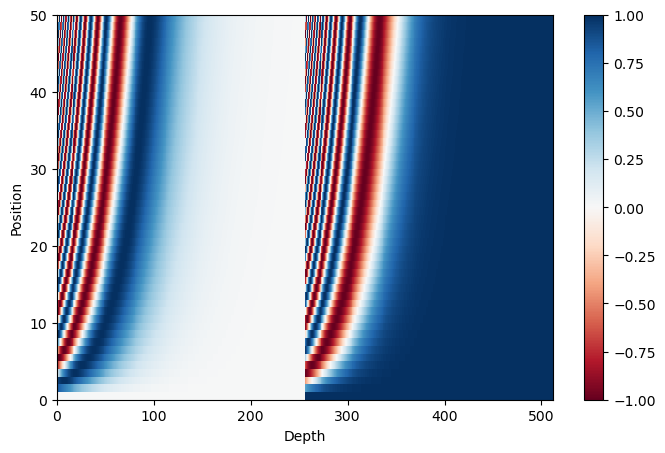

In [110]:
sample_pos_encoding = PositionalEncoding(50, 512)

plt.figure(figsize=(8, 5))
plt.pcolormesh(sample_pos_encoding.pos_encoding.numpy()[0], cmap='RdBu')
plt.xlabel('Depth')
plt.xlim((0, 512))
plt.ylabel('Position')
plt.colorbar()
plt.show()

### Capa del codificador

In [111]:
def encoder_layer(units, d_model, num_heads, dropout, name="encoder_layer"):
    inputs = tf.keras.Input(shape=(None, d_model), name="inputs")
    padding_mask = tf.keras.Input(shape=(1, 1, None), name="padding_mask")

    attention = MultiHeadAttention(
        d_model, num_heads, name="attention")({
            'query': inputs, 'key': inputs, 'value': inputs, 'mask': padding_mask})
    attention = tf.keras.layers.Dropout(rate=dropout)(attention)
    add_attention = tf.keras.layers.add([inputs, attention])
    attention = tf.keras.layers.LayerNormalization(epsilon=1e-6)(add_attention)

    outputs = tf.keras.layers.Dense(units=units, activation='relu')(attention)
    outputs = tf.keras.layers.Dense(units=d_model)(outputs)
    outputs = tf.keras.layers.Dropout(rate=dropout)(outputs)
    add_attention = tf.keras.layers.add([attention, outputs])
    outputs = tf.keras.layers.LayerNormalization(epsilon=1e-6)(add_attention)

    return tf.keras.Model(inputs=[inputs, padding_mask], outputs=outputs, name=name)


sample_encoder_layer = encoder_layer(
    units=512, d_model=128, num_heads=4, dropout=0.3, name="sample_encoder_layer")
try:
    tf.keras.utils.plot_model(sample_encoder_layer, to_file='encoder_layer.png', show_shapes=True)
    print('Diagrama guardado: encoder_layer.png')
except Exception as e:
    print('No se pudo generar diagrama:', e)

You must install pydot (`pip install pydot`) for `plot_model` to work.
Diagrama guardado: encoder_layer.png


### Codificador

In [112]:
def encoder(vocab_size, num_layers, units, d_model, num_heads, dropout,
            name="encoder"):
    inputs = tf.keras.Input(shape=(None,), name="inputs")
    padding_mask = tf.keras.Input(shape=(1, 1, None), name="padding_mask")

    #embeddings = tf.keras.layers.Embedding(vocab_size, d_model, sparse=False)(inputs)
    embeddings = tf.keras.layers.Embedding(vocab_size, d_model)(inputs)
    embeddings = embeddings * tf.math.sqrt(tf.cast(d_model, tf.float32))
    embeddings = PositionalEncoding(MAX_LENGTH, d_model)(embeddings)
    outputs = tf.keras.layers.Dropout(rate=dropout)(embeddings)

    for i in range(num_layers):
        outputs = encoder_layer(
            units=units, d_model=d_model, num_heads=num_heads, dropout=dropout,
            name="encoder_layer_{}".format(i),
        )([outputs, padding_mask])

    return tf.keras.Model(inputs=[inputs, padding_mask], outputs=outputs, name=name)


sample_encoder = encoder(
    vocab_size=VOCAB_SIZE, num_layers=2, units=512, d_model=128, num_heads=4,
    dropout=0.3, name="sample_encoder")
sample_encoder.summary()
try:
    tf.keras.utils.plot_model(sample_encoder, to_file='encoder.png', show_shapes=True)
    print('Diagrama guardado: encoder.png')
except Exception as e:
    print('No se pudo generar diagrama:', e)

Model: "sample_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ inputs (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 128) │  1,048,576 │ inputs[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, None, 128) │          0 │ embedding_2[0][0] │
│ (Multiply)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encodin… │ (None, None, 128) │          0 │ multiply_2[0][0]  │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, None, 128) │          0 │ positional_encod… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ padding_mask        │ (None, 1, 1,      │          0 │ -                 │
│ (InputLayer)        │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_layer_0     │ (None, None, 128) │    198,272 │ dropout_12[0][0], │
│ (Functional)        │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_layer_1     │ (None, None, 128) │    198,272 │ encoder_layer_0[… │
│ (Functional)        │                   │            │ padding_mask[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,445,120 (5.51 MB)

 Trainable params: 1,445,120 (5.51 MB)

 Non-trainable params: 0 (0.00 B)

You must install pydot (`pip install pydot`) for `plot_model` to work.
Diagrama guardado: encoder.png


### Capa decodificadora

In [113]:
def decoder_layer(units, d_model, num_heads, dropout, name="decoder_layer"):
    inputs = tf.keras.Input(shape=(None, d_model), name="inputs")
    enc_outputs = tf.keras.Input(shape=(None, d_model), name="encoder_outputs")
    look_ahead_mask = tf.keras.Input(shape=(1, None, None), name="look_ahead_mask")
    padding_mask = tf.keras.Input(shape=(1, 1, None), name='padding_mask')

    attention1 = MultiHeadAttention(
        d_model, num_heads, name="attention_1")(inputs={
            'query': inputs, 'key': inputs, 'value': inputs, 'mask': look_ahead_mask})
    add_attention = tf.keras.layers.add([attention1, inputs])
    attention1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)(add_attention)

    attention2 = MultiHeadAttention(
        d_model, num_heads, name="attention_2")(inputs={
            'query': attention1, 'key': enc_outputs, 'value': enc_outputs, 'mask': padding_mask})
    attention2 = tf.keras.layers.Dropout(rate=dropout)(attention2)
    add_attention = tf.keras.layers.add([attention2, attention1])
    attention2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)(add_attention)

    outputs = tf.keras.layers.Dense(units=units, activation='relu')(attention2)
    outputs = tf.keras.layers.Dense(units=d_model)(outputs)
    outputs = tf.keras.layers.Dropout(rate=dropout)(outputs)
    add_attention = tf.keras.layers.add([outputs, attention2])
    outputs = tf.keras.layers.LayerNormalization(epsilon=1e-6)(add_attention)

    return tf.keras.Model(
        inputs=[inputs, enc_outputs, look_ahead_mask, padding_mask],
        outputs=outputs, name=name)


sample_decoder_layer = decoder_layer(
    units=512, d_model=128, num_heads=4, dropout=0.3, name="sample_decoder_layer")
try:
    tf.keras.utils.plot_model(sample_decoder_layer, to_file='decoder_layer.png', show_shapes=True)
    print('Diagrama guardado: decoder_layer.png')
except Exception as e:
    print('No se pudo generar diagrama:', e)

You must install pydot (`pip install pydot`) for `plot_model` to work.
Diagrama guardado: decoder_layer.png


### Decodificador

In [114]:
def decoder(vocab_size, num_layers, units, d_model, num_heads, dropout,
            name='decoder'):
    inputs = tf.keras.Input(shape=(None,), name='inputs')
    enc_outputs = tf.keras.Input(shape=(None, d_model), name='encoder_outputs')
    look_ahead_mask = tf.keras.Input(shape=(1, None, None), name='look_ahead_mask')
    padding_mask = tf.keras.Input(shape=(1, 1, None), name='padding_mask')

    #embeddings = tf.keras.layers.Embedding(vocab_size, d_model, sparse=False)(inputs)
    embeddings = tf.keras.layers.Embedding(vocab_size, d_model)(inputs)
    embeddings = embeddings * tf.math.sqrt(tf.cast(d_model, tf.float32))
    embeddings = PositionalEncoding(MAX_LENGTH, d_model)(embeddings)
    outputs = tf.keras.layers.Dropout(rate=dropout)(embeddings)

    for i in range(num_layers):
        outputs = decoder_layer(
            units=units, d_model=d_model, num_heads=num_heads, dropout=dropout,
            name='decoder_layer_{}'.format(i),
        )(inputs=[outputs, enc_outputs, look_ahead_mask, padding_mask])

    return tf.keras.Model(
        inputs=[inputs, enc_outputs, look_ahead_mask, padding_mask],
        outputs=outputs, name=name)


sample_decoder = decoder(
    vocab_size=VOCAB_SIZE, num_layers=2, units=512, d_model=128, num_heads=4,
    dropout=0.3, name="sample_decoder")
sample_decoder.summary()
try:
    tf.keras.utils.plot_model(sample_decoder, to_file='decoder.png', show_shapes=True)
    print('Diagrama guardado: decoder.png')
except Exception as e:
    print('No se pudo generar diagrama:', e)

Model: "sample_decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ inputs (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, None, 128) │  1,048,576 │ inputs[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_3          │ (None, None, 128) │          0 │ embedding_3[0][0] │
│ (Multiply)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encodin… │ (None, None, 128) │          0 │ multiply_3[0][0]  │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_19          │ (None, None, 128) │          0 │ positional_encod… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_outputs     │ (None, None, 128) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ look_ahead_mask     │ (None, 1, None,   │          0 │ -                 │
│ (InputLayer)        │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ padding_mask        │ (None, 1, 1,      │          0 │ -                 │
│ (InputLayer)        │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_layer_0     │ (None, None, 128) │    264,576 │ dropout_19[0][0], │
│ (Functional)        │                   │            │ encoder_outputs[… │
│                     │                   │            │ look_ahead_mask[… │
│                     │                   │            │ padding_mask[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_layer_1     │ (None, None, 128) │    264,576 │ decoder_layer_0[… │
│ (Functional)        │                   │            │ encoder_outputs[… │
│                     │                   │            │ look_ahead_mask[… │
│                     │                   │            │ padding_mask[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,577,728 (6.02 MB)

 Trainable params: 1,577,728 (6.02 MB)

 Non-trainable params: 0 (0.00 B)

You must install pydot (`pip install pydot`) for `plot_model` to work.
Diagrama guardado: decoder.png


### Transformer completo

In [115]:
def transformer(vocab_size, num_layers, units, d_model, num_heads, dropout,
                name="transformer"):
    inputs = tf.keras.Input(shape=(None,), name="inputs")
    dec_inputs = tf.keras.Input(shape=(None,), name="dec_inputs")

    enc_padding_mask = tf.keras.layers.Lambda(
        create_padding_mask, name='enc_padding_mask')(inputs)
    look_ahead_mask = tf.keras.layers.Lambda(
        create_look_ahead_mask, name='look_ahead_mask')(dec_inputs)
    dec_padding_mask = tf.keras.layers.Lambda(
        create_padding_mask, name='dec_padding_mask')(inputs)

    enc_outputs = encoder(
        vocab_size=vocab_size, num_layers=num_layers, units=units,
        d_model=d_model, num_heads=num_heads, dropout=dropout,
    )(inputs=[inputs, enc_padding_mask])

    dec_outputs = decoder(
        vocab_size=vocab_size, num_layers=num_layers, units=units,
        d_model=d_model, num_heads=num_heads, dropout=dropout,
    )(inputs=[dec_inputs, enc_outputs, look_ahead_mask, dec_padding_mask])

    outputs = tf.keras.layers.Dense(units=vocab_size, name="outputs")(dec_outputs)

    return tf.keras.Model(
        inputs={'inputs': inputs, 'dec_inputs': dec_inputs},
        outputs=outputs,
        name=name)


sample_transformer = transformer(
    vocab_size=VOCAB_SIZE, num_layers=2, units=512, d_model=128, num_heads=4,
    dropout=0.3, name="sample_transformer")
sample_transformer.summary()
try:
    tf.keras.utils.plot_model(sample_transformer, to_file='transformer.png', show_shapes=True)
    print('Diagrama guardado: transformer.png')
except Exception as e:
    print('No se pudo generar diagrama:', e)

Model: "sample_transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ inputs (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_inputs          │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_padding_mask    │ (None, 1, 1,      │          0 │ inputs[0][0]      │
│ (Lambda)            │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder             │ (None, None, 128) │  1,445,120 │ inputs[0][0],     │
│ (Functional)        │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ look_ahead_mask     │ (None, 1, None,   │          0 │ dec_inputs[0][0]  │
│ (Lambda)            │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_padding_mask    │ (None, 1, 1,      │          0 │ inputs[0][0]      │
│ (Lambda)            │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder             │ (None, None, 128) │  1,577,728 │ dec_inputs[0][0], │
│ (Functional)        │                   │            │ encoder[0][0],    │
│                     │                   │            │ look_ahead_mask[… │
│                     │                   │            │ dec_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ outputs (Dense)     │ (None, None,      │  1,056,768 │ decoder[0][0]     │
│                     │ 8192)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,079,616 (15.56 MB)

 Trainable params: 4,079,616 (15.56 MB)

 Non-trainable params: 0 (0.00 B)

You must install pydot (`pip install pydot`) for `plot_model` to work.
Diagrama guardado: transformer.png


## <span style="color:blue">Entrenamiento del modelo</span>

In [116]:
def loss_function(y_true, y_pred):
    y_true = tf.reshape(y_true, shape=(-1, MAX_LENGTH - 1))
    loss = tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True, reduction='none')(y_true, y_pred)
    mask = tf.cast(tf.not_equal(y_true, 0), tf.float32)
    loss = tf.multiply(loss, mask)
    return tf.reduce_mean(loss)

In [117]:
class CustomSchedule(tf.keras.optimizers.schedules.LearningRateSchedule):

    def __init__(self, d_model, warmup_steps=4000):
        super().__init__()
        self.d_model = tf.cast(d_model, tf.float32)
        self.warmup_steps = tf.cast(warmup_steps, tf.float32)   # también float32

    def get_config(self):
        return {
            "d_model": float(self.d_model.numpy()),"warmup_steps": float(self.warmup_steps.numpy()),
        }

    def __call__(self, step):
        step = tf.cast(step, tf.float32)                        # <-- ESTO arregla el error
        arg1 = tf.math.rsqrt(step)
        arg2 = step * tf.math.pow(self.warmup_steps, -1.5)
        return tf.math.multiply(tf.math.rsqrt(self.d_model),tf.math.minimum(arg1, arg2))

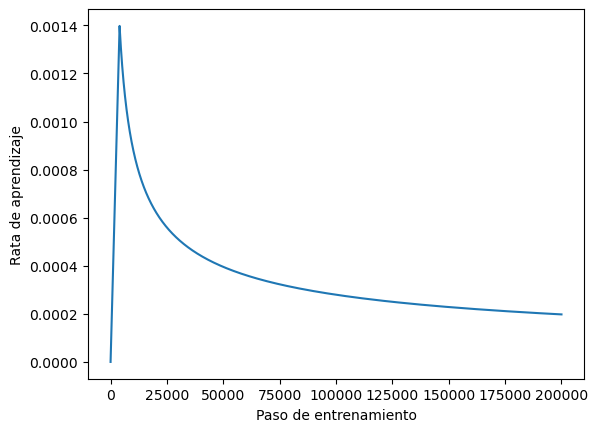

In [118]:
sample_learning_rate = CustomSchedule(d_model=128)

plt.plot(sample_learning_rate(tf.range(200000, dtype=tf.float32)))
plt.ylabel("Rata de aprendizaje")
plt.xlabel("Paso de entrenamiento")
plt.show()

### Inicializar y compilar el modelo

In [119]:
tf.keras.backend.clear_session()

learning_rate = CustomSchedule(D_MODEL)
optimizer = tf.keras.optimizers.Adam(
    learning_rate, beta_1=0.9, beta_2=0.98, epsilon=1e-9)

def accuracy(y_true, y_pred):
    y_true = tf.reshape(y_true, shape=(-1, MAX_LENGTH - 1))
    return tf.keras.metrics.sparse_categorical_accuracy(y_true, y_pred)

with strategy.scope():
    model = transformer(
        vocab_size=VOCAB_SIZE,
        num_layers=NUM_LAYERS,
        units=UNITS,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        dropout=DROPOUT)
    model.compile(optimizer=optimizer, loss=loss_function, metrics=[accuracy])

model.summary()

Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ inputs (InputLayer) │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_inputs          │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc_padding_mask    │ (None, 1, 1,      │          0 │ inputs[0][0]      │
│ (Lambda)            │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder             │ (None, None, 512) │ 10,506,240 │ inputs[0][0],     │
│ (Functional)        │                   │            │ enc_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ look_ahead_mask     │ (None, 1, None,   │          0 │ dec_inputs[0][0]  │
│ (Lambda)            │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dec_padding_mask    │ (None, 1, 1,      │          0 │ inputs[0][0]      │
│ (Lambda)            │ None)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder             │ (None, None, 512) │ 14,712,832 │ dec_inputs[0][0], │
│ (Functional)        │                   │            │ encoder[0][0],    │
│                     │                   │            │ look_ahead_mask[… │
│                     │                   │            │ dec_padding_mask… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ outputs (Dense)     │ (None, None,      │  4,202,496 │ decoder[0][0]     │
│                     │ 8192)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 29,421,568 (112.23 MB)

 Trainable params: 29,421,568 (112.23 MB)

 Non-trainable params: 0 (0.00 B)

### Ajusta el modelo

In [120]:
model.fit(dataset, epochs=EPOCHS)

Epoch 1/100


W0000 00:00:1794184081.051180    1546 assert_op.cc:38] Ignoring Assert operator compile_loss/loss_function/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert


352/353 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.0298 - loss: 2.4684

W0000 00:00:1794184192.484444    1541 assert_op.cc:38] Ignoring Assert operator compile_loss/loss_function/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert


353/353 ━━━━━━━━━━━━━━━━━━━━ 202s 285ms/step - accuracy: 0.0299 - loss: 2.4665
Epoch 2/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 32s 92ms/step - accuracy: 0.0718 - loss: 1.5467
Epoch 3/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 31s 88ms/step - accuracy: 0.0831 - loss: 1.3937
Epoch 4/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.0883 - loss: 1.3274
Epoch 5/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.0926 - loss: 1.2785
Epoch 6/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.0963 - loss: 1.2404
Epoch 7/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 32s 89ms/step - accuracy: 0.0989 - loss: 1.1969
Epoch 8/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 32s 90ms/step - accuracy: 0.1028 - loss: 1.1680
Epoch 9/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.1054 - loss: 1.1203
Epoch 10/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 32s 89ms/step - accuracy: 0.1073 - loss: 1.0927
Epoch 11/100
353/353 ━━━━━━━━━━━━━━━━━━━━ 31s 89ms/step - accuracy: 0.1102 - loss: 1.0592
Epoch 12/100
353/353 ━━━━━━━━

## <span style="color:blue">Evaluación y predicción</span>

In [121]:
def evaluate(sentence):
    sentence = preprocess_sentence(sentence)
    sentence_ids = START_TOKEN + encode(sentence) + END_TOKEN
    sentence = tf.expand_dims(tf.constant(sentence_ids, dtype=tf.int32), axis=0)
    output = tf.expand_dims(tf.constant(START_TOKEN, dtype=tf.int32), axis=0)
    for i in range(MAX_LENGTH):
        predictions = model({'inputs': sentence, 'dec_inputs': output}, training=False)
        predictions = predictions[:, -1:, :]
        predicted_id = tf.cast(tf.argmax(predictions, axis=-1), tf.int32)
        if tf.equal(predicted_id, END_TOKEN[0]):
            break
        output = tf.concat([output, predicted_id], axis=-1)
    return tf.squeeze(output, axis=0)


def predict(sentence):
    prediction = evaluate(sentence)
    predicted_sentence = decode(prediction.numpy())
    print('Input : {}'.format(sentence))
    print('Output: {}'.format(predicted_sentence))
    return predicted_sentence

In [122]:
_ = predict('Where have you been?')

Input : Where have you been?
Output: she is up for it .


In [123]:
_ = predict("It's a trap")

Input : It's a trap
Output: do it ! i want to get higher !


In [124]:
sentence = 'I am not crazy, my mother had me tested.'
for _ in range(5):
    sentence = predict(sentence)
    print('')

Input : I am not crazy, my mother had me tested.
Output: it is a goddamn wild goose chase . remember when commander powell found that plus probability of sentient life in the <unk> cloud ?

Input : it is a goddamn wild goose chase . remember when commander powell found that plus probability of sentient life in the <unk> cloud ?
Output: well , there s the possibility of . . .

Input : well , there s the possibility of . . .
Output: so what did you want ? i think we understand each other , no ?

Input : so what did you want ? i think we understand each other , no ?
Output: i am sure .

Input : i am sure .
Output: i do not know what you are talking about , howard .



## <span style="color:blue">Resumen</span>

Transformer encoder–decoder funcional en Keras 3 / Python 3.12.

Cambios clave respecto a la versión que fallaba:
* `PositionalEncoding.compute_output_shape()` añadido: evita que Keras 3 trace `call()` con un `KerasTensor sparse` (causa del `TypeError: Expected float32, but got SparseTensor(...)`).
* `MultiHeadAttention.compute_output_shape()` añadido por robustez.
* `embeddings = embeddings * sqrt(d_model)` (en vez de `*=`) y `Embedding(..., sparse=False)` explícito: evita que el flag sparse se propague.
* Descarga del corpus con `cache_dir='.'` + búsqueda recursiva de `movie_lines.txt`: no depende de la carpeta `_extracted` interna de Keras.
* `MultiHeadAttention` usa reshape/transpose nativos (sin `Lambda`).
* `predict` usa `decode()` propio (no hay `SubwordTextEncoder`).